<!-- ## Phase 01: Signal EDA & Acoustic Feature Engineering

### Objective
In Phase 0, I started the process of EDA through checking the Metadata associated with the audio dataset alone. In this Phase, I will establish clean, leakage-free acoustic representations from the 1,440-utterance RAVDESS corpus. 

This is the phase where I take a look at the audio files themselves. After performing some basic spot checks, I will use the [LibRosa MFCC](https://librosa.org/doc/main/api/generated/librosa.feature.mfcc.html) library. This is a popular open-source library used to analzye digital audio and perform feature extraction. I plan to

- validates lexical and duration balance
- go beyond the spoken statements and isolate individual vocal signs that indicate emotion (e.g. sighs, whimpers)
- check for artifacts like noise and 
- a mapping of the raw 16kHz signlas into a structured, *low dimensional* feature space that I can use for the next phase of modeling

### Primary Deliverable
`data/processed/ser_features.parquet` — A structured tabular dataset comprising 1,440 clips across verified metadata labels and engineered acoustic descriptors, ready for speaker-independent cross-validation.

### Key Goals
1. **Lexical & Duration Invariance:** Statement identity ("Kids..." vs. "Dogs...") exhibits uniform duration distributions across emotional classes, proving **statement phrasing is not a predictive confounder**. 

    This will help identify if clip duration can be justified as a viable predictive feature or if it introduces bias.

2. **Audio Cleanup:** Raw audio clips could contain leading/trailing studio silence. I will check for this by analyzing the waveforms and trying an energy-based silence trimming (`top_db=25`). 
 
    The goal is to isolate the **active signal** while preserving expressive acoustic transients (sobs, sighs, and emphatic aspirated stops)
   
3. **Feature Extraction**: After performing cleanup of the clips and outliers, the ultiamte goal of this phase is to determine w**hich specific acoustic features** carry discriminatory signal to structure the pipeline stages (e.g., separating gender routing features from emotion classification features).

   * **Spectral Envelope & Timbre:** 13 MFCCs plus first-order deltas ($\Delta$) capture static vocal-tract geometry and dynamic spectral transitions over time.
   * **Fundamental Frequency ($F_0$):** Extracted via probabilistic YIN (`pyin`) across voiced segments to establish pitch baseline and variance—critical for Stage 1 gender routing and Stage 2 arousal discrimination.
   * **Energy & Spectral Dynamics:** Root Mean Square (RMS) energy, Spectral Centroid, Bandwidth, Rolloff, Flatness, and Zero-Crossing Rate quantify vocal effort, brightness, and harmonicity.

4. Finally, I would like to perform a **multicollinearity audit** and see if I could prune redundant acoustic statistics to prevent variance inflation in linear and tree-based estimators before moving to formal feature selection or Ridge/Lasso regularization. This can be done through pairwise correlation checks (|r| ≥ 0.85), as well as exploring open-source signal processing techniques like the **Discrete Cosine Transform (DCT)** to decorrelate overlapping filterbanks and truncate high-frequency acoustic noise. -->

In [ ]:
from pathlib import Path
import IPython.display as ipd
import librosa
import librosa.display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import soundfile as sf

In [ ]:
#  define input/output paths for this phase
project_root = Path.cwd().resolve().parent
metadata_path = project_root / "data" / "processed" / "00_ravdess_metadata.csv"

output_dir = project_root / "data" / "processed"
output_dir.mkdir(parents=True, exist_ok=True)

In [ ]:
# Load metadata generated in Phase 0: Metadata EDA
df_metadata = pd.read_csv(metadata_path)
print(f"Loaded {len(df_metadata)} records from {metadata_path.name}")
df_metadata.head(3)

Loaded 1440 records from 00_ravdess_metadata.csv


,file_name,file_path,actor_id,gender,emotion,intensity,statement,repetition
0,03-01-01-01-01-01-01.wav,/Users/abhisheknigam/workspace/github/my-ai/sp...,1,M,neutral,normal,Kids are talking by the door,1
1,03-01-01-01-01-02-01.wav,/Users/abhisheknigam/workspace/github/my-ai/sp...,1,M,neutral,normal,Kids are talking by the door,2
2,03-01-01-01-02-01-01.wav,/Users/abhisheknigam/workspace/github/my-ai/sp...,1,M,neutral,normal,Dogs are sitting by the door,1


In [ ]:
df_metadata.info()

<class 'pandas.DataFrame'>
RangeIndex: 1440 entries, 0 to 1439
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   file_name   1440 non-null   str  
 1   file_path   1440 non-null   str  
 2   actor_id    1440 non-null   int64
 3   gender      1440 non-null   str  
 4   emotion     1440 non-null   str  
 5   intensity   1440 non-null   str  
 6   statement   1440 non-null   str  
 7   repetition  1440 non-null   int64
dtypes: int64(2), str(6)
memory usage: 380.9 KB


## Audio Cleanup

### Investigating Clip Duration
Augmenting the metadata with raw clip durations to verify length consistency and assess silence padding across recordings.

In [ ]:
durations = []
for file_path in df_metadata["file_path"]:
    # Resolve absolute path if stored relative
    full_path = (
        project_root / file_path if not Path(file_path).is_absolute() else file_path
    )
    durations.append(librosa.get_duration(path=full_path))

df_metadata["duration_sec"] = durations

In [ ]:
print("Updated Metadata (abridged)")
print(df_metadata[['file_name', 'statement', 'duration_sec']].sample(3))

Updated Metadata (abridged)
                     file_name                     statement  duration_sec
1310  03-01-07-02-02-01-22.wav  Dogs are sitting by the door      4.204208
1055  03-01-05-02-02-02-18.wav  Dogs are sitting by the door      4.237563
690   03-01-05-01-02-01-12.wav  Dogs are sitting by the door      3.737083


In [ ]:
# # # save intermediate
# target_path = output_dir / "01_1_df_metadata_with_duration.parquet"
# df_metadata.to_parquet(str(target_path.resolve()), index=False)

# print(f"Successfully serialized: {target_path.resolve()}")

# # reload if necessary
# df_loaded = pd.read_parquet(target_path)

Successfully serialized: /Users/abhisheknigam/workspace/github/my-ai/speech-emotion-router/data/processed/01_1_df_metadata_with_duration.parquet


In [ ]:
# check overall stats
print("Audio Duration Summary (seconds):")
print(df_metadata["duration_sec"].describe().round(2))

Audio Duration Summary (seconds):
count    1440.00
mean        3.70
std         0.34
min         2.94
25%         3.47
50%         3.67
75%         3.87
max         5.27
Name: duration_sec, dtype: float64


In [ ]:
duration_by_statement = (
    df_metadata.groupby("statement")["duration_sec"]
    .agg(
        count="count",
        mean="mean",
        std="std",
        median="median",
        min="min",
        max="max",
    )
    .round(2)
)

print("Duration (seconds) by Statement:")
print(duration_by_statement)

Duration (seconds) by Statement:
                              count  mean   std  median   min   max
statement                                                          
Dogs are sitting by the door    720  3.68  0.34    3.64  2.94  5.11
Kids are talking by the door    720  3.72  0.34    3.69  3.07  5.27


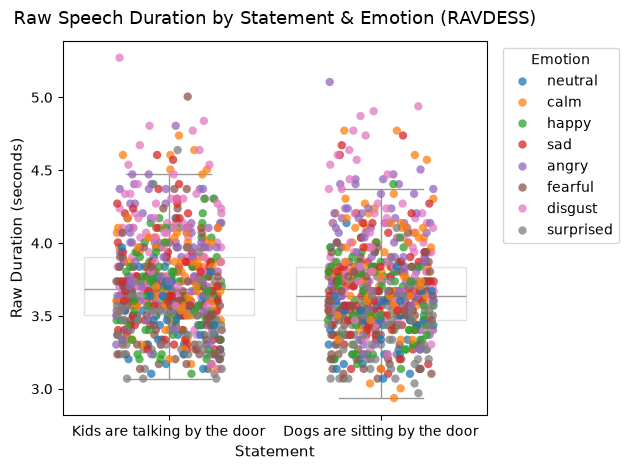

In [ ]:
sns.stripplot(
    data=df_metadata,
    x="statement",
    y="duration_sec",
    hue="emotion",
    jitter=0.25,
    alpha=0.75,
    size=6,
    palette="tab10",
)

# Overlay subtle boxplots to show median and IQR per statement
sns.boxplot(
    data=df_metadata,
    x="statement",
    y="duration_sec",
    color="white",
    boxprops=dict(alpha=0.3),
    showcaps=True,
    showfliers=False,
)

plt.title(
    "Raw Speech Duration by Statement & Emotion (RAVDESS)",
    fontsize=13,
    pad=12,
)
plt.xlabel("Statement", fontsize=11)
plt.ylabel("Raw Duration (seconds)", fontsize=11)
plt.legend(
    title="Emotion",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    frameon=True,
)
plt.tight_layout()
plt.show()

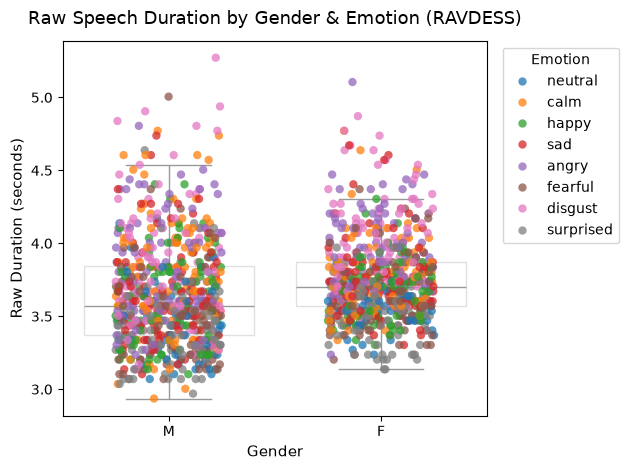

In [ ]:
sns.stripplot(
    data=df_metadata,
    x="gender",
    y="duration_sec",
    hue="emotion",
    jitter=0.25,
    alpha=0.75,
    size=6,
    palette="tab10",
)

# Overlay subtle boxplots to show median and IQR per statement
sns.boxplot(
    data=df_metadata,
    x="gender",
    y="duration_sec",
    color="white",
    boxprops=dict(alpha=0.3),
    showcaps=True,
    showfliers=False,
)

plt.title(
    "Raw Speech Duration by Gender & Emotion (RAVDESS)",
    fontsize=13,
    pad=12,
)
plt.xlabel("Gender", fontsize=11)
plt.ylabel("Raw Duration (seconds)", fontsize=11)
plt.legend(
    title="Emotion",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    frameon=True,
)
plt.tight_layout()
plt.show()

In [ ]:
outliers_high = df_metadata.sort_values(by="duration_sec", ascending=False)
outliers_high[['file_name', 'gender', 'emotion', 'duration_sec']].head(5)

,file_name,gender,emotion,duration_sec
1129,03-01-07-02-01-02-19.wav,M,disgust,5.271937
1415,03-01-05-02-02-02-24.wav,F,angry,5.105104
40,03-01-06-02-01-01-01.wav,M,fearful,5.005000
1131,03-01-07-02-02-02-19.wav,M,disgust,4.938271
1130,03-01-07-02-02-01-19.wav,M,disgust,4.904896


Top Outlier:
file_name                                03-01-07-02-01-02-19.wav
file_path       /Users/abhisheknigam/workspace/github/my-ai/sp...
actor_id                                                       19
gender                                                          M
emotion                                                   disgust
intensity                                                  strong
statement                            Kids are talking by the door
repetition                                                      2
duration_sec                                             5.271937
Name: 1129, dtype: object


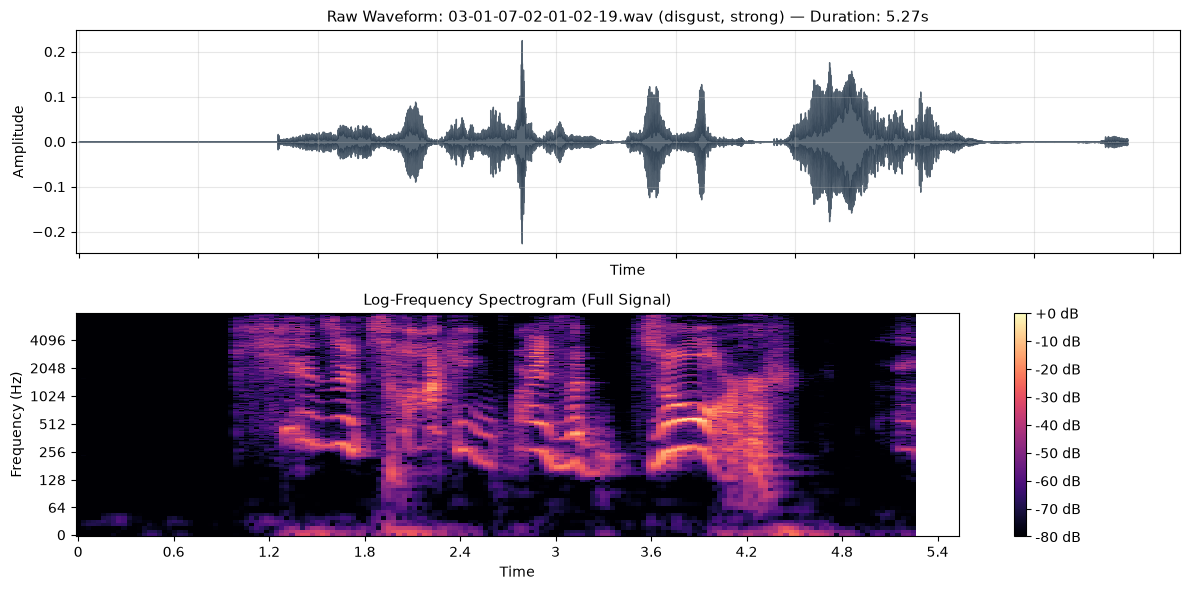

Raw Audio Playback (5.27s):


In [ ]:
# Pull the top outlier clip directly from outliers_high
top_outlier = outliers_high.iloc[0]
print(f"Top Outlier:\n{top_outlier}")
clip_name = top_outlier["file_name"] # 03-01-07-02-01-02-19.wav	
clip_path = top_outlier["file_path"]

# Load audio at standard 16 kHz
sr = 16000
y, _ = librosa.load(clip_path, sr=sr)
raw_dur = len(y) / sr

# Compute Log-Frequency Spectrogram (dB magnitude)
D = librosa.amplitude_to_db(np.abs(librosa.stft(y)), ref=np.max)

# Double Plot
fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)

# Top: Raw Waveform
librosa.display.waveshow(y, sr=sr, ax=axes[0], color="#2c3e50", alpha=0.8)
axes[0].set_title(
    f"Raw Waveform: {clip_name} ({top_outlier['emotion']}, {top_outlier['intensity']}) — Duration: {raw_dur:.2f}s",
    fontsize=11,
)
axes[0].set_ylabel("Amplitude")
axes[0].grid(True, alpha=0.3)

# Bottom: Spectrogram
img = librosa.display.specshow(
    D, sr=sr, x_axis="time", y_axis="log", ax=axes[1], cmap="magma"
)
axes[1].set_title("Log-Frequency Spectrogram (Full Signal)", fontsize=11)
axes[1].set_ylabel("Frequency (Hz)")
fig.colorbar(img, ax=axes[1], format="%+2.0f dB")

plt.tight_layout()
plt.show()

# Audio Player
print(f"Raw Audio Playback ({raw_dur:.2f}s):")
ipd.display(ipd.Audio(y, rate=sr))

### Audio Whitespace Removal
Benchmarking `librosa.effects.trim` across dB thresholds to strip boundary padding while preserving natural speech onsets and decays.

Examining the log-frequency spectrogram reveals two distinct categories of silence: 
- continuous, pitch-black regions at the recording boundaries (around `0.0`s to `1.1`s and `4.8`s to `5.27`s), and
- brief vertical dark bands mid-utterance (around `2.4`s and `3.4`s).

While boundary dead zones represent pure studio buffer, the internal pauses correspond to natural stops and dramatic timing inherent to the actor's emotional delivery.

The spectrogram maps power logarithmically against the file's loudest frame set as the baseline reference at **`0` dB** (full scale). Any sound quieter than that peak yields a fractional ratio, which evaluates to a negative value. 

*(Grounding this in audio engineering fundamentals—referenced from domain guides like [NCH Software's Audio Concepts](https://help.nchsoftware.com/help/en/wavepad/win/concepts.html)—helps clarify how these relative metrics translate to amplitude):*

- Every drop of **`-6` dB** roughly halves acoustic amplitude; **`-20` dB** represents one-tenth amplitude, and **`-80` dB** marks the near-silent studio noise floor (`1/10,000`th of peak).
- Speech processing conventions for clean studio voice recommend a dynamic cutoff between `20` dB and `30` dB below peak frame energy to capture faint phonation while rejecting room tone.
- Visual inspection shows formant energy decaying sharply past **`-25` dB** at true onset and offset points, while playback confirms this cutoff retains soft consonant attacks without clipping.

Therefore, to balance silence outliers with acoustic benchmarks, I will use **`top_db=25`** (discarding frames below **`-25` dB**) as my calibrated trimming threshold and see if the data can be cleaned up this way.

In [ ]:
# Helper function to extract whitespace stats
def spot_check_silence( # use top_db = 25
    file_path, top_db=25, frame_length=1024, hop_length=256
):
    # Read raw audio without full librosa pipeline overhead
    y, sr = sf.read(file_path)

    # Convert to mono if multi-channel
    if y.ndim > 1:
        y = np.mean(y, axis=1)

    raw_dur = len(y) / sr

    # Compute short-time energy (squared amplitude over frames)
    # Using librosa's built-in fast trimming directly on raw samples
    y_trimmed, trim_idx = librosa.effects.trim(
        y, top_db=top_db, frame_length=frame_length, hop_length=hop_length
    )

    lead_silence = trim_idx[0] / sr
    trail_silence = (len(y) - trim_idx[1]) / sr
    active_dur = len(y_trimmed) / sr
    silence_ratio = (lead_silence + trail_silence) / raw_dur * 100

    return {
        "raw_dur": raw_dur,
        "lead_silence": lead_silence,
        "trail_silence": trail_silence,
        "active_dur": active_dur,
        "silence_ratio": silence_ratio,
        "y": y,
        "y_trimmed": y_trimmed,
        "sr": sr,
        "trim_idx": trim_idx,
    }

Try the identification to clean up the example audio clip

File: 03-01-07-02-01-02-19.wav
- Raw Duration:    5.27s
- Lead Removed:    1.13s
- Trail Removed:   0.78s
- Active Duration: 3.37s
- Silence Ratio:   36.1%


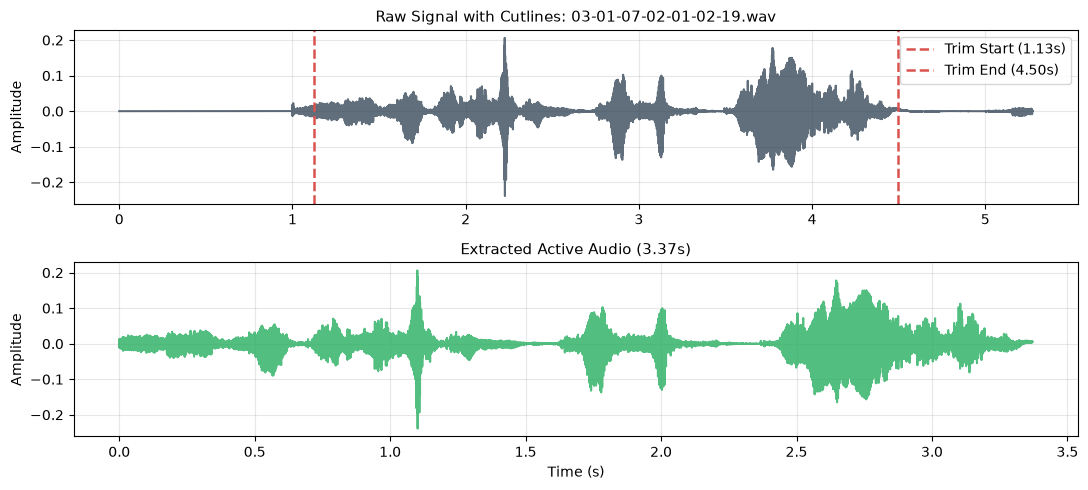

Playback Trimmed Audio (Verifying active phonation capture):


In [74]:
res = spot_check_silence(clip_path, top_db=25)

# Print verification metrics
print(f"File: {clip_name}")
print(f"- Raw Duration:    {res['raw_dur']:.2f}s")
print(f"- Lead Removed:    {res['lead_silence']:.2f}s")
print(f"- Trail Removed:   {res['trail_silence']:.2f}s")
print(f"- Active Duration: {res['active_dur']:.2f}s")
print(f"- Silence Ratio:   {res['silence_ratio']:.1f}%")

# Plot Raw (with cutlines) vs. Trimmed Waveforms
fig, axes = plt.subplots(2, 1, figsize=(11, 5), sharey=True)

# Raw Signal
t_raw = np.linspace(0, res["raw_dur"], len(res["y"]))
axes[0].plot(t_raw, res["y"], color="#2c3e50", alpha=0.75)
axes[0].axvline(
    res["lead_silence"],
    color="#d9534f",
    linestyle="--",
    linewidth=1.8,
    label=f"Trim Start ({res['lead_silence']:.2f}s)",
)
axes[0].axvline(
    res["raw_dur"] - res["trail_silence"],
    color="#d9534f",
    linestyle="--",
    linewidth=1.8,
    label=f"Trim End ({res['raw_dur'] - res['trail_silence']:.2f}s)",
)
axes[0].set_title(f"Raw Signal with Cutlines: {clip_name}", fontsize=11)
axes[0].set_ylabel("Amplitude")
axes[0].legend(loc="upper right")
axes[0].grid(True, alpha=0.3)

# Trimmed Signal
t_trim = np.linspace(0, res["active_dur"], len(res["y_trimmed"]))
axes[1].plot(t_trim, res["y_trimmed"], color="#27ae60", alpha=0.8)
axes[1].set_title(
    f"Extracted Active Audio ({res['active_dur']:.2f}s)", fontsize=11
)
axes[1].set_xlabel("Time (s)")
axes[1].set_ylabel("Amplitude")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Playback Trimmed Audio
print("Playback Trimmed Audio (Verifying active phonation capture):")
ipd.display(ipd.Audio(res["y_trimmed"], rate=res["sr"]))

I think that the result is quite good. The audio was reduced by `36.1%` and still had:

- the main speaking portion and the inflections and silences are present
- the leading silence is removed
- the last bit which has a bit of noise artifact is also removed

I can use this process tocleanup all the files.

In [86]:
#  build df_silence_audit with all metadata + audit columns
results = []
for _, row in outliers_high.iterrows():
    res = spot_check_silence(row["file_path"], top_db=25)

    record = row.to_dict()
    record.update(
        {
            "raw_dur": round(res["raw_dur"], 2),
            "lead_silence": round(res["lead_silence"], 2),
            "trail_silence": round(res["trail_silence"], 2),
            "active_dur": round(res["active_dur"], 2),
            "silence_%": round(res["silence_ratio"], 1),
        }
    )
    results.append(record)

df_silence_audit = pd.DataFrame(results)

#  Find the "active_delta" i.e how much is the diff
df_silence_audit["silence_delta"] = (
    df_silence_audit["duration_sec"] - df_silence_audit["active_dur"]
).round(2)

In [89]:
df_silence_audit[['lead_silence', 'trail_silence', 'duration_sec', 'active_dur'
                  , 'silence_%', 'silence_delta']].describe()


,lead_silence,trail_silence,duration_sec,active_dur,silence_%,silence_delta
count,1440.000000,1440.000000,1440.000000,1440.000000,1440.000000,1440.000000
mean,0.985840,0.970507,3.700665,1.744028,53.231250,1.956347
std,0.130167,0.184828,0.336676,0.392327,7.569321,0.238883
min,0.000000,0.000000,2.936271,1.000000,8.400000,0.290000
25%,1.000000,0.960000,3.470146,1.480000,50.575000,1.950000
50%,1.010000,1.000000,3.670333,1.670000,54.800000,2.010000
75%,1.020000,1.050000,3.870542,1.940000,57.900000,2.060000
max,1.410000,1.450000,5.271937,3.570000,66.600000,2.510000


Running the silence audit across the entire dataset (`1,440` audio files) reveals the following structural characteristics:

- **Preponderance of Silence**: An average of `53.2%` (median `54.8%`) of audio duration across the dataset consists of unvoiced room tone, peaking as high as `66.6%` in some clips.
- **Systematic Studio Buffers**: Leading silence (`mean = 0.99`s, `std = 0.13`s) and trailing silence (`mean = 0.97`s, `std = 0.18`s) show tight clustering around `1.0`s, reflecting fixed studio recording cues.
- **Total Silence Removed (`silence_delta`)**: Trimming removes an average of `1.96`s (median `2.01`s, `std = 0.24`s) of dead air per clip—ranging from `0.29`s to `2.51`s—reclaiming over half of each file's total duration.
- **Active Speech Distribution**: True phonation duration spans from `1.00`s to `3.57`s (`mean = 1.74`s, `std = 0.39`s), capturing authentic emotional pacing and sentence inflections.

**Preprocessing Decision**: Trimming with `top_db=25` strips the artificial ~`1.0`s buffers from both ends (~`1.96`s total dead air on average), ensuring that downstream acoustic feature extraction (e.g., MFCCs) operates solely on voiced phonation rather than studio floor noise.

In [ ]:
# # save intermediate
# target_path = output_dir / "01_2_duration_outliers_w_silence.parquet"
# df_silence_audit.to_parquet(str(target_path.resolve()), index=False)

# print(f"Successfully serialized: {target_path.resolve()}")

# # reload if necessary
# df_loaded = pd.read_parquet(target_path)

Successfully serialized: /Users/abhisheknigam/workspace/github/my-ai/speech-emotion-router/data/processed/01_2_duration_outliers_w_silence.parquet


### Evaluating Other Cleanup Strategies

With boundary trimming established at `top_db=25`, we must evaluate whether further acoustic cleanups are warranted.

Standard voiceover post-production relies on corrective filtering (see [Listen2It: *Audio Cleanup Techniques*](https://www.getlisten2it.com/blog/audio-cleanup-techniques-fix-noisy-recordings-like-a-pro/)):

> - ***High-Pass Filtering (Low-Cut):** Rolling off rumble below 80–100 Hz caused by HVAC, handling, or electrical hum.*
> - ***Spectral De-noising & Noise Gating:** Profiling ambient noise prints to subtract persistent hiss or mute audio between spoken words.*
> - ***De-essing & De-clicking:** Taming harsh high-frequency sibilance ('s', 'sh') and eliminating mouth clicks/saliva transients.*
> - ***Compression & Peak Normalization:** Evening out dynamic swings to bring overall dialogue volume up to a uniform broadcast loudness level.*

However, cleanup necessity depends strictly on acquisition conditions. According to the RAVDESS protocol ([Livingstone & Russo, 2018](https://journals.plos.org/plosone/article?id=10.1371/journal.pone.0196391)):

> *"Actors were recorded individually in a professional recording studio... Microphone output was recorded using Pro Tools 8 and a Digidesign 003 mixing workstation, at a sampling rate of 48 kHz, 16 bit, with files saved in uncompressed wave format."*
> 
> *"Audio-only files were exported as lossless wave format, at 48 kHz."*

Applying aggressive post-processing to clean studio audio degrades features critical to Speech Emotion Recognition (SER):
- **Spectral Distortion:** Denoising, gating, and de-essing introduce phase artifacts and strip subtle emotional cues—such as breathiness, phonation decay, and high-frequency vocal tract articulation.
- **Loss of Dynamic Arousal:** Normalization and compression squash natural variations in vocal intensity and sound pressure level (SPL), destroying the dynamic energy contrast that separates low-arousal states (*Sadness*) from high-arousal bursts (*Anger*).

To empirically confirm these pristine baseline conditions hold, we verify spot-check samples below for **digital clipping**

In [91]:
# Build spot_samples directly from df_silence_audit
spot_samples = [
    # 1. Male Actor (Actor 1) - Low Arousal baseline
    df_silence_audit[
        (df_silence_audit["actor_id"] == 1)
        & (df_silence_audit["emotion"] == "neutral")
    ].iloc[0],
    # 2. Male Actor (Actor 1) - Low Arousal / Negative Valence
    df_silence_audit[
        (df_silence_audit["actor_id"] == 1)
        & (df_silence_audit["emotion"] == "sad")
        & (df_silence_audit["intensity"] == "normal")
    ].iloc[0],
    # 3. Male Actor (Actor 1) - High Arousal / Negative Valence
    df_silence_audit[
        (df_silence_audit["actor_id"] == 1)
        & (df_silence_audit["emotion"] == "angry")
        & (df_silence_audit["intensity"] == "strong")
    ].iloc[0],
    # 4. Female Actor (Actor 2) - High Arousal / Negative Valence (Gender contrast against #3)
    df_silence_audit[
        (df_silence_audit["actor_id"] == 2)
        & (df_silence_audit["emotion"] == "angry")
        & (df_silence_audit["intensity"] == "strong")
    ].iloc[0],
    # 5. Male Actor (Actor 1) - High Arousal / Positive Valence
    df_silence_audit[
        (df_silence_audit["actor_id"] == 1)
        & (df_silence_audit["emotion"] == "happy")
        & (df_silence_audit["intensity"] == "strong")
    ].iloc[0],
    # 6. Female Actor (Actor 2) - High Arousal / Positive Valence (Gender contrast against #5)
    df_silence_audit[
        (df_silence_audit["actor_id"] == 2)
        & (df_silence_audit["emotion"] == "happy")
        & (df_silence_audit["intensity"] == "strong")
    ].iloc[0],
]

# Verify selection
print(f"Instantiated {len(spot_samples)} spot sample records:")
for s in spot_samples:
    print(
        f"- Actor {s['actor_id']:02d} ({s['gender'].upper()}): "
        f"{s['emotion']} ({s['intensity']}) | File: {s['file_name']}"
    )

Instantiated 6 spot sample records:
- Actor 01 (M): neutral (normal) | File: 03-01-01-01-01-02-01.wav
- Actor 01 (M): sad (normal) | File: 03-01-04-01-01-01-01.wav
- Actor 01 (M): angry (strong) | File: 03-01-05-02-02-02-01.wav
- Actor 02 (F): angry (strong) | File: 03-01-05-02-02-01-02.wav
- Actor 01 (M): happy (strong) | File: 03-01-03-02-02-02-01.wav
- Actor 02 (F): happy (strong) | File: 03-01-03-02-02-02-02.wav


In [92]:
# Quick sanity check on signal health across spot samples
cleanliness_check = []

for sample in spot_samples:
    y, _ = librosa.load(sample["file_path"], sr=16000)
    cleanliness_check.append(
        {
            "file": sample["file_name"],
            "emotion": sample["emotion"],
            "max_abs_amp": round(float(np.max(np.abs(y))), 4),
            "dc_offset": round(float(np.mean(y)), 6),
            "clipped_samples": int(np.sum(np.abs(y) >= 0.999)),
        }
    )

display(pd.DataFrame(cleanliness_check))

,file,emotion,max_abs_amp,dc_offset,clipped_samples
0,03-01-01-01-01-02-01.wav,neutral,0.0475,0.000001,0
1,03-01-04-01-01-01-01.wav,sad,0.0457,0.000000,0
2,03-01-05-02-02-02-01.wav,angry,0.9971,-0.000043,0
3,03-01-05-02-02-01-02.wav,angry,0.9902,0.000000,0
4,03-01-03-02-02-02-01.wav,happy,0.1399,0.000001,0
5,03-01-03-02-02-02-02.wav,happy,0.3040,0.000000,0


#### Findings

The audited sample metrics confirm that destructive audio cleanups are unnecessary:

- **No De-clipping Needed (`clipped_samples = 0`):** Peak amplitudes reach at most $0.9971$, safely avoiding flat-topped waveform saturation on loud vocal bursts.
- **No High-Pass Detrending Needed (`dc_offset` $\approx 0.0$):** Mean signal displacement sits near zero ($-0.000043$ to $0.000001$), confirming hardware calibration without baseline drift.
- **No Amplitude Normalization Allowed:** Peak amplitudes span from $\approx 0.046$ (*Sad*) to $\approx 0.997$ (*Angry*). This ~20× dynamic range reflects natural vocal intensity and acoustic arousal; normalizing volume levels would artificially erase this separation.
- **No Spectral Denoising Needed:** The studio baseline environment exhibits no broadband hiss or HVAC hum that would justify risking phase distortion through noise subtraction.

**Conclusion:** On-the-fly silence boundary trimming (`top_db=25`) remains the only signal modification applied before feature extraction.